<a href="https://colab.research.google.com/github/pramaspx/PM-Turi4-clustering/blob/main/PM_Pertemuan8_Praktikum_AhmadMiftahHadiPramanaArsjad_2488010057.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

data = {
    'usia': [19, 21, 22, 25, 28, 30, 35, 40, 45, 50,
             23, 26, 32, 38, 42, 48, 55, 60, 27, 33],
    'pendapatan': [3000000, 3500000, 4000000, 5000000,
                   6000000, 6500000, 8000000, 9000000,
                   10000000, 12000000, 3200000, 4500000,
                   7000000, 8500000, 9500000, 11000000,
                   13000000, 15000000, 5500000, 7500000],
    'skor_belanja': [85, 90, 78, 75, 60, 65, 50, 45, 40, 30,
                     88, 80, 55, 48, 42, 35, 25, 20, 70, 58]
}
df = pd.DataFrame(data)
X_scaled = StandardScaler().fit_transform(df)


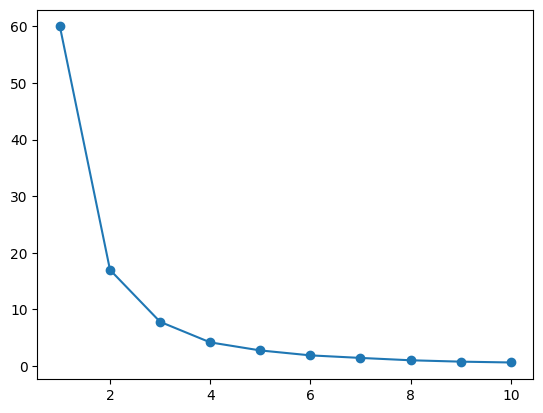

In [ ]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
1    9
2    7
0    4
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.5196801750994765


In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja
cluster                                
0        53.2  12750000.0          27.5
1        24.6   4577777.8          76.8
2        37.9   8500000.0          48.3


LATIHAN MANDIRI

6.

In [ ]:
#6
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
1    6
2    5
0    4
4    3
3    2
Name: count, dtype: int64


In [ ]:
#6
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.4629139556831232


- Hasil K=3 :0.5196801750994765
- Hasil K=5 :0.4629139556831232

7.

In [ ]:
#7
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

data = {
    'usia': [19, 21, 22, 25, 28, 30, 35, 40, 45, 50,
             23, 26, 32, 38, 42, 48, 55, 60, 27, 33],
    'pendapatan': [3000000, 3500000, 4000000, 5000000,
                   6000000, 6500000, 8000000, 9000000,
                   10000000, 12000000, 3200000, 4500000,
                   7000000, 8500000, 9500000, 11000000,
                   13000000, 15000000, 5500000, 7500000],
    'skor_belanja': [85, 90, 78, 75, 60, 65, 50, 45, 40, 30,
                     88, 80, 55, 48, 42, 35, 25, 20, 70, 58]
}
df = pd.DataFrame(data)

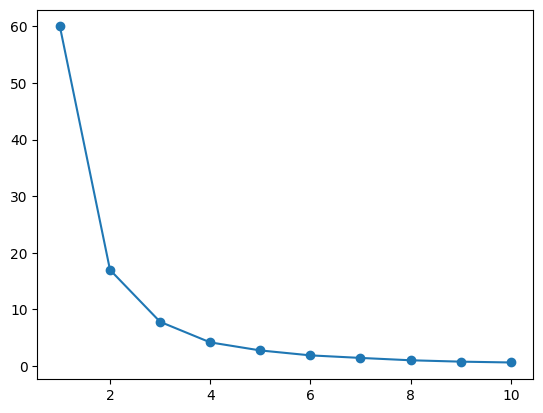

In [ ]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
1    9
2    7
0    4
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.5196801750994765


- Dengan scaling:0.5196801750994765
- Tanpa scaling:0.5196801750994765
- Kesimpulannya, tidak perbedaan antara yang scaling dengan yang tidak di scaling.



8.

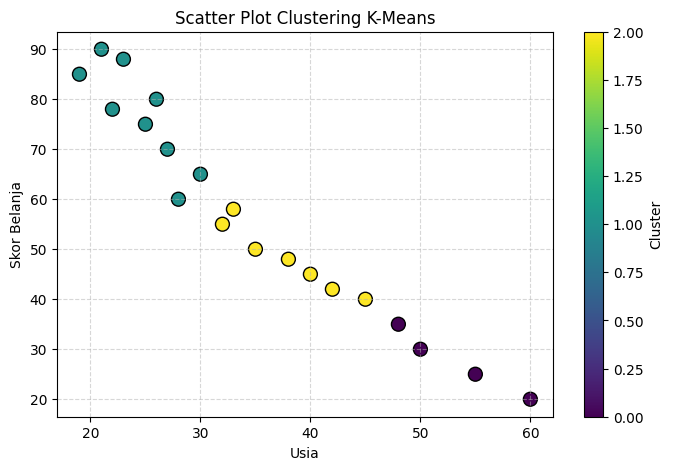

In [ ]:
# Scatter plot cluster: usia vs skor_belanja
plt.figure(figsize=(8, 5))

plt.scatter(
    df['usia'],
    df['skor_belanja'],
    c=df['cluster'],
    cmap='viridis',
    s=100,
    edgecolors='black'
)

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Clustering K-Means')
plt.colorbar(label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()